(16 Oct 2026: JY and JM)

## Notebook for the sloped Eady problem focusing on transient growth

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from matplotlib.lines import Line2D
from scipy.linalg import expm, svd, eig, sqrtm, eigh
from scipy.optimize import fsolve
zi = 1j

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "mathtext.fontset": "cm",
    "mathtext.rm": "serif",
    "font.size": 11,
    "image.cmap": "RdBu_r"
})

letters = "abcdefghijklmnopqrstuvwxyz"

## 0) Define some useful subroutines to be called later

In [2]:
def Eady_A(k, l, delta, Bu):    
    mu = Bu * np.sqrt(k**2 + l**2)
    A = -zi*k*np.array([
            [1.0-np.cosh(2*mu)/(mu*np.sinh(2*mu)), -1/(mu*np.sinh(2*mu))],
            [(1.0-delta)/(mu*np.sinh(2*mu)), -(1.0-(1.0-delta)*np.cosh(2*mu)/(mu*np.sinh(2*mu)))]
        ])
    return A

def Eady_M(k, l, Bu):   # Energy matrix for Eady
    mu = Bu * np.sqrt(k**2 + l**2)
    M = np.array([
            [np.cosh(2*mu), 1],
            [1, np.cosh(2*mu)]
        ])
    M /= mu*np.sinh(2*mu)
    return M

def instantaneous(A, W):
    T = sqrtm(W)
    B = T @ A @ np.linalg.inv(T)
    eigvals, eigvecs = eig((B + B.conj().T)/2)
    idx = np.argmax(np.real(eigvals))
    growth = eigvals[idx]
    q_tilde = eigvecs[:, idx]
    q = np.linalg.inv(T) @ q_tilde
    return growth, q

def finite_time_optimal(t, A, M):
    P = expm(A * t)
    T = sqrtm(M)
    D = T @ P @ np.linalg.inv(T)
    _, S, Vh = svd(D)
    amp = S[0]
    x0 = Vh.conj().T[:, 0]
    q0 = np.linalg.inv(T) @ x0
    qt = P @ q0
    return amp, q0, qt

def dF_eady(points, k, delta, l, Bu):
    mu = Bu * np.sqrt(k**2 + l**2)
    deps, gamma = points
    eps_dot = (2.0 * k / (mu * np.sinh(2.0*mu))*
        ((1.0 - 0.5*delta) * np.cosh(2.0*mu)- mu * np.sinh(2.0*mu)
        + (1.0 / np.sin(2.0*gamma)- 0.5*delta*np.tan(gamma)) * np.cos(deps)))

    gamma_dot = (
        k / (mu * np.sinh(2.0*mu))*np.sin(deps)
        *(np.cos(2.0*gamma)+ delta * np.sin(gamma)**2))
    return eps_dot, gamma_dot


def get_root_eady(dF, k, delta, guess_init):
    return fsolve(dF,guess_init,args=(k, delta, l, Bu))

def state_to_phase(q):
    qT, qB = q
    deps = np.angle(qT/qB)
    gamma = np.arctan(np.abs(qT/qB))
    return deps, gamma

def compute_optimal(T_vecs, A, M):
    deps_list = []
    gamma_list = []
    for T in T_vecs:
        _, q0, _ = finite_time_optimal(T, A, M)
        deps, Gamma = state_to_phase(q0)
        deps_list.append(deps)
        gamma_list.append(Gamma)
    return np.array(deps_list), np.array(gamma_list)

def plot_root(ax, root):
    eps = root[0] / np.pi
    gamma = root[1] / np.pi

    style = dict(marker='^', markersize=8, markerfacecolor='none', markeredgewidth=1, color='k')

    ax.plot(eps, gamma, **style)

    if np.isclose(eps, -1, atol=1e-3):
        ax.plot(1, gamma, **style)
    elif np.isclose(eps, 1, atol=1e-3):
        ax.plot(-1, gamma, **style)

## 1) Compute relevant quantities for NM, instantaneous and transient growth in enstrophy and energy norm

In [3]:
# k_vec = np.linspace(1e-3, 2, 301)
k_vec = np.concat([10 ** np.linspace(-3, -1, 201), np.linspace(1e-1, 2, 301)])  # JM: add a zoom for small k values
delta_vec = [0.5, 0.0, -0.5]
l_vec = [0.0, 0.5]
# l = 0
Bu = 1.0

Eady_growth_NM = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_eps_NM = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_Gamma_NM = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_growth_ens = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_eps_ens = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_Gamma_ens = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_growth_enr = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_eps_enr = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_Gamma_enr = np.zeros((len(k_vec), len(delta_vec), 2))
Eady_Delta_max = np.zeros((len(k_vec), len(delta_vec), 2))
normality = np.zeros((len(k_vec), len(delta_vec), 2))
normality_enr = np.zeros((len(k_vec), len(delta_vec), 2))

for ll, l in enumerate(l_vec):
    for j, delta in enumerate(delta_vec):
        for i, k in enumerate(k_vec):
            A = Eady_A(k, l, delta, Bu)
            M = Eady_M(k, l, Bu)
            eigvals, eigvecs = eig(A)
            idx = np.argmax(np.real(eigvals))
            Eady_growth_NM[i, j, ll] = np.real(eigvals[idx])
            if Eady_growth_NM[i, j, ll]>1e-4:
                q = eigvecs[:, idx]
            else:
                id = np.argmax(np.imag(eigvals))
                q = eigvecs[:, id]
            Eady_eps_NM[i, j, ll], Eady_Gamma_NM[i, j, ll] = np.arccos(np.cos(np.angle(q[0]/q[-1]))), np.arctan(np.abs(q[0]/q[-1]))

            growth, q = instantaneous(A, np.eye(2))
            Eady_growth_ens[i, j, ll] = np.real(growth)
            Eady_eps_ens[i, j, ll], Eady_Gamma_ens[i, j, ll] = state_to_phase(q)

            growth, q = instantaneous(A, M)
            Eady_growth_enr[i, j, ll] = np.real(growth)
            Eady_eps_enr[i, j, ll], Eady_Gamma_enr[i, j, ll] = state_to_phase(q)

            commutator = A @ A.conj().T - A.conj().T @ A
            normality[i, j, ll] = np.linalg.norm(commutator)

            T = sqrtm(M)
            D = T @ A @ np.linalg.inv(T)
            commutator = D @ D.conj().T - D.conj().T @ D
            normality_enr[i, j, ll] = np.linalg.norm(commutator)


        # Eady_Delta_max[:, j, ll] = 2*Eady_eps_NM[:, j, ll] -np.pi

In [4]:
# compute NM growth k_max for diff. delta
Eady_k_max = np.zeros((len(delta_vec), 2))
for ll in range(len(l_vec)):
    for j in range(len(delta_vec)):
        k_max_idx = np.argmax(Eady_growth_NM[:, j, ll])
        Eady_k_max[j, ll] = k_vec[k_max_idx]
        print(rf'delta={delta_vec[j]}, l={l_vec[ll]}, k_max={Eady_k_max[j, ll]}, growth rate: {Eady_growth_NM[k_max_idx, j, ll]:.4f}')

delta=0.5, l=0.0, k_max=0.5623333333333334, growth rate: 0.3616
delta=0.0, l=0.0, k_max=0.8029999999999999, growth rate: 0.3098
delta=-0.5, l=0.0, k_max=1.1640000000000001, growth rate: 0.2145
delta=0.5, l=0.5, k_max=0.537, growth rate: 0.2410
delta=0.0, l=0.5, k_max=0.7396666666666666, growth rate: 0.2511
delta=-0.5, l=0.5, k_max=1.069, growth rate: 0.1941


In [5]:
# compute effective optimal growth in enstrophy and energy norm for selected target time
# t_vals = np.linspace(0.0, 5.0, 201)
t_vals = [1.0, 3.0, 5.0]
# l = 0.0
Bu = 1.0

Eady_effective_ens = np.zeros((len(k_vec), len(delta_vec), len(t_vals), 2))
Eady_effective_enr = np.zeros((len(k_vec), len(delta_vec), len(t_vals), 2))

for ll, l in enumerate(l_vec):
    for j, delta in enumerate(delta_vec):
        for i, k in enumerate(k_vec):
            A = Eady_A(k, l, delta, Bu)
            M = Eady_M(k, l, Bu)
            for d, t in enumerate(t_vals):
                amp_ens, _, _ = finite_time_optimal(t, A, np.eye(2)) # Euclidean norm growth
                amp_enr, _, _ = finite_time_optimal(t, A, M) # Energy norm growth
                Eady_effective_ens[i, j, d, ll] = np.log(amp_ens)/t
                Eady_effective_enr[i, j, d, ll] = np.log(amp_enr)/t

In [6]:
# compute streamfunction of optimal perturbation at selected target time in enstrophy and energy norm
z_vec = np.linspace(-1, 1, 31)
t = 5.0
psi0_B = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
psi0_T = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
# psit_B = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
# psit_T = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
psi0_B_enr = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
psi0_T_enr = np.zeros((len(z_vec), 501, 3, 3, 2), dtype=complex)
# psit_B_enr = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
# psit_T_enr = np.zeros((len(z_vec), 501, 2, 2), dtype=complex)
for ll, l in enumerate(l_vec):
    for j, idx in enumerate([0, 1, 2]):
        delta = delta_vec[idx]
        for i, k_idx in enumerate([0, 1, 2]):
            k = Eady_k_max[k_idx, ll]
            x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
            mu = Bu * np.sqrt(k**2 + l**2)
            A = Eady_A(k, l, delta, Bu)
            M = Eady_M(k, l, Bu)
            _, q0, qt = finite_time_optimal(t, A, np.eye(2))
            _, q0_enr, qt_enr = finite_time_optimal(t, A, M)

            q0[0] /= q0[1]
            qt[0] /= qt[1]
            q0[1] = 1.0
            qt[1] = 1.0
            q0_enr[0] /= q0_enr[1]
            qt_enr[0] /= qt_enr[1]
            q0_enr[1] = 1.0
            qt_enr[1] = 1.0

            Z = z_vec[:, None]
            X = x_vec[None, :]
            psi0_B[:, :, i, j, ll] = np.exp(zi * k * X) * (-q0[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
            psi0_T[:, :, i, j, ll] = np.exp(zi * k * X) * (-q0[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

            # psit_B[:, :, i, j] = np.exp(zi * k * X) * (-qt[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
            # psit_T[:, :, i, j] = np.exp(zi * k * X) * (-qt[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

            psi0_B_enr[:, :, i, j, ll] = np.exp(zi * k * X) * (-q0_enr[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
            psi0_T_enr[:, :, i, j, ll] = np.exp(zi * k * X) * (-q0_enr[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

            # psit_B_enr[:, :, i, j] = np.exp(zi * k * X) * (-qt_enr[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
            # psit_T_enr[:, :, i, j] = np.exp(zi * k * X) * (-qt_enr[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

field0 = psi0_T + psi0_B
# fieldt = psit_T + psit_B
diff0 = np.angle(field0[-1, 0, :, :]/field0[0, 0, :, :])
# difft = np.angle(fieldt[-1, 0, :, :]/fieldt[0, 0, :, :])

field0_enr = psi0_T_enr + psi0_B_enr
# fieldt_enr = psit_T_enr + psit_B_enr
diff0_enr = np.angle(field0_enr[-1, 0, :, :]/field0_enr[0, 0, :, :])
# difft_enr = np.angle(fieldt_enr[-1, 0, :, :]/fieldt_enr[0, 0, :, :])

## 2) Generating figures from the paper

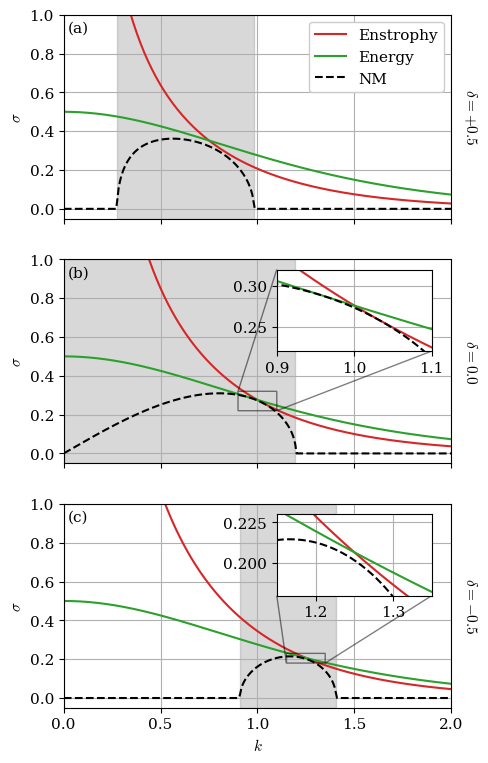

In [7]:
# figure2 （growth rate)
fig, axs = plt.subplots(3, 1, figsize=(5, 9), sharex=True)
ll = 0
for j, ax in enumerate(axs):
    ax.plot(k_vec, Eady_growth_ens[:, j, ll],'C3', label='Enstrophy')
    ax.plot(k_vec, Eady_growth_enr[:, j, ll],'C2', label='Energy')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', label='NM')
    ax.set_xlim(0, 2)
    ax.set_ylim(-0.05, 1.0)
    ax.set_ylabel(r"$\sigma$")
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.grid()
    ax.set_xticks([0, 0.5, 1.0, 1.5, 2.0])
    ax.text(0.01, 0.97, f"({letters[j]})", transform=ax.transAxes, ha='left', va='top')
    if j == 1:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Eady_growth_ens[:, j, ll],'C3')
        ax_inset.plot(k_vec, Eady_growth_enr[:, j, ll],'C2')
        ax_inset.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(0.9, 1.1)
        ax_inset.set_ylim(0.22, 0.32)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")
        
    if j == 2:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Eady_growth_ens[:, j, ll],'C3')
        ax_inset.plot(k_vec, Eady_growth_enr[:, j, ll],'C2')
        ax_inset.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(1.15, 1.35)
        ax_inset.set_ylim(0.18, 0.23)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")

for row, ax in enumerate(axs):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1].set_xlabel(r"$k$")
axs[0].legend(loc='upper right', framealpha=1.0)
# fig.savefig('figure/figure2.pdf', bbox_inches='tight')

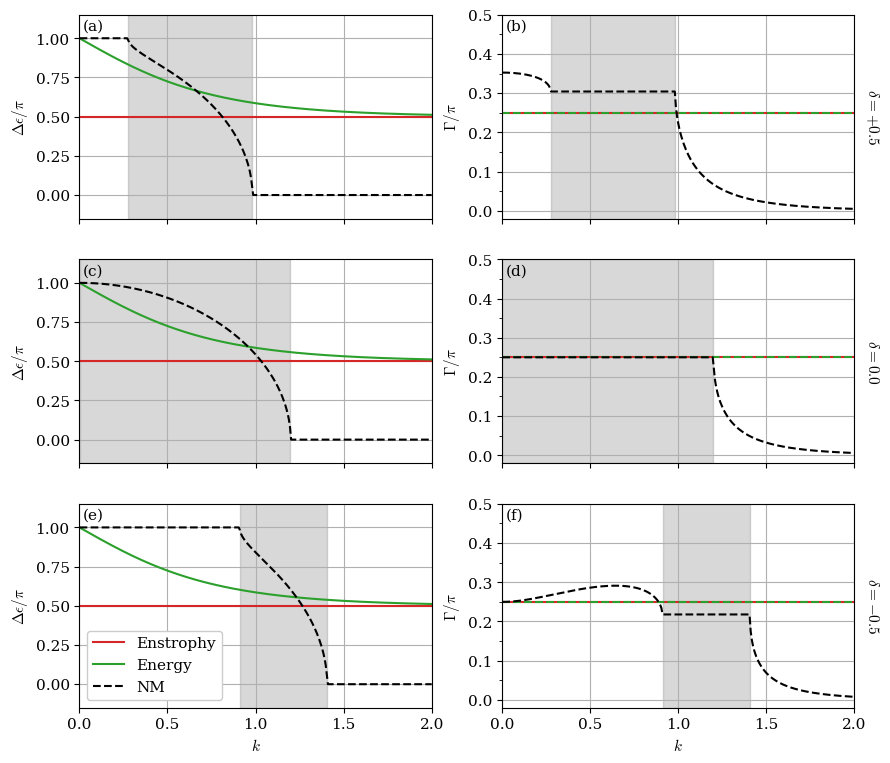

In [8]:
# figure3 (CRW quantities)
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
ll = 0
for j in range(3):
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    ax.plot(k_vec, Eady_eps_ens[:, j, ll]/np.pi, 'C3', label='Enstrophy')
    ax.plot(k_vec, Eady_eps_enr[:, j, ll]/np.pi, 'C2', label='Energy')
    ax.plot(k_vec, Eady_eps_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylim([-0.15, 1.15])
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    ax.set_ylabel(r'$\Delta\epsilon/\pi$')
    
    ax = axs[j, 1]
    ax.plot(k_vec, Eady_Gamma_ens[:, j, ll]/np.pi, 'C3', label='Enstrophy')
    ax.plot(k_vec, Eady_Gamma_enr[:, j, ll]/np.pi, 'C2--', label='Energy')
    ax.plot(k_vec, Eady_Gamma_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylabel(r'$\Gamma/\pi$')
    ax.set_ylim(-0.02, 0.5)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top')  

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 2)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1,0].legend(loc='lower left', framealpha=1.0)
# fig.savefig('figure/figure3.pdf', bbox_inches='tight')

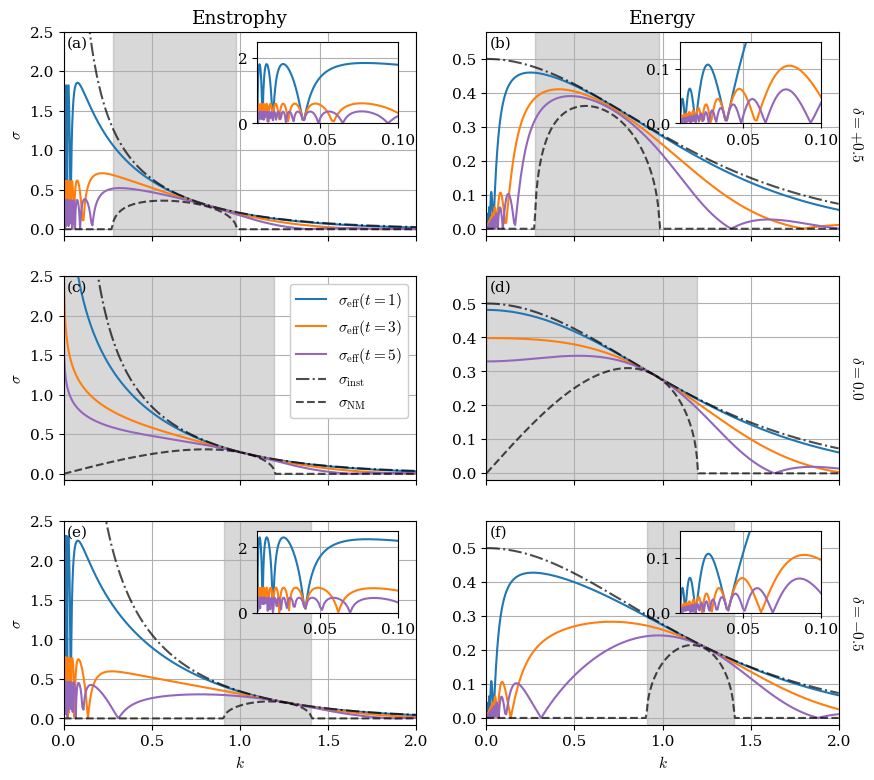

In [9]:
# figure4 (effective optimal growth rate)
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
colors = ['C0', 'C1', 'C4']
ll = 0
for j in range(3):
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Eady_effective_ens[:, j, d, ll], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Eady_growth_ens[:, j, ll], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', alpha=0.7, label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Enstrophy' if j == 0 else "")
    ax.set_ylim(-0.08, 2.5)
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    ax.set_ylabel(r"$\sigma$")

    if j != 1:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        for d, t in enumerate(t_vals):
            ax_inset.plot(k_vec, Eady_effective_ens[:, j, d, ll], color=colors[d])
        
        ax_inset.set_xlim(1e-2, 1e-1)
        ax_inset.set_ylim(0.0, 2.5)
        ax_inset.grid()
    
    ax = axs[j, 1]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Eady_effective_enr[:, j, d, ll], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Eady_growth_enr[:, j, ll], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', alpha=0.7, label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Energy' if j == 0 else "")
    ax.set_ylim(-0.02, 0.58)
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top') 

    if j != 1:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        for d, t in enumerate(t_vals):
            ax_inset.plot(k_vec, Eady_effective_enr[:, j, d, ll], color=colors[d])
        
        ax_inset.set_xlim(1e-2, 1e-1)
        ax_inset.set_ylim(0.0, 0.15)
        ax_inset.grid()

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 2)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

axs[1,0].legend(loc='upper right', framealpha=1.0)
# fig.savefig('figure/figure4.pdf', bbox_inches='tight')

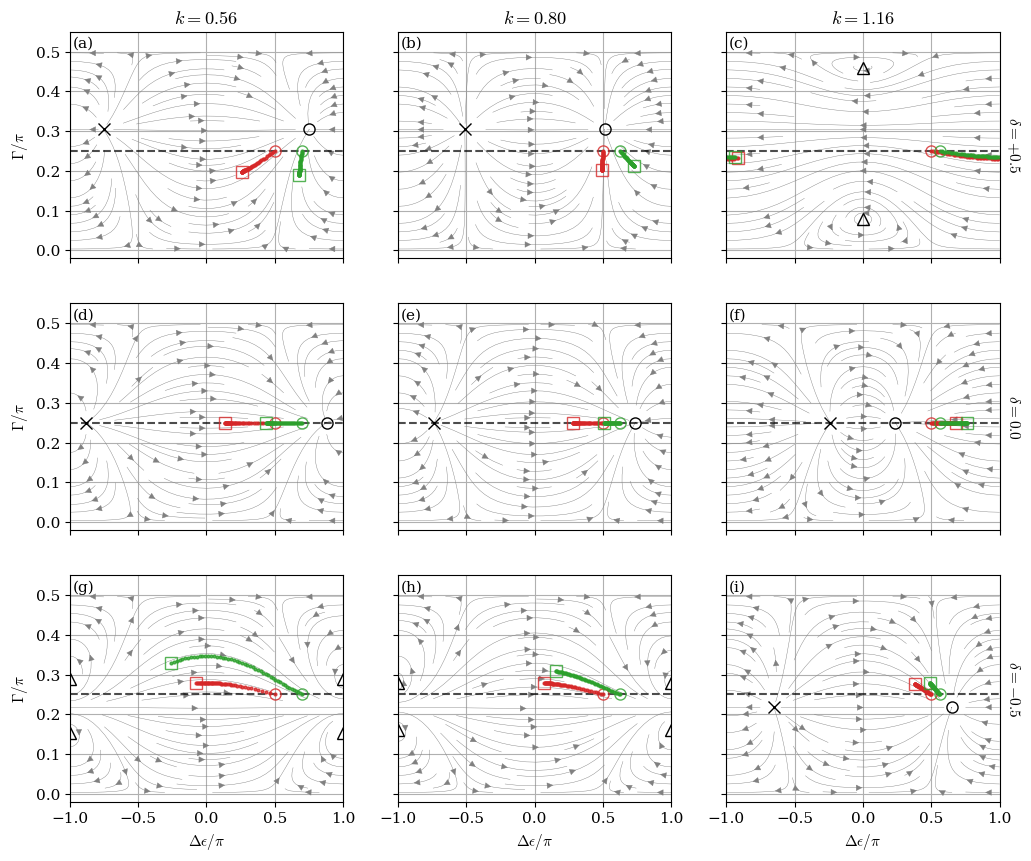

In [10]:
# figure5 (phase portrait)
dummy = 0

ll = 0
l = l_vec[ll]
k_vals = Eady_k_max[:, ll]
T_vecs = np.linspace(1e-3, 5.0, 51)
# T_vecs = np.linspace(50, 500, 51)
fig, axs = plt.subplots(3,3,figsize=(12,10),sharex=True,sharey=True)

for row, delta in enumerate(delta_vec):
    for col, k in enumerate(k_vals):
        ax = axs[row, col]
        deps_grid, gamma_grid = np.meshgrid(np.linspace(-np.pi, np.pi, 101),np.linspace(0.01, np.pi/2 - 0.01, 101))
        points = np.asarray([deps_grid, gamma_grid])
        eps_dot, gamma_dot = dF_eady(points,k,delta,l,Bu)
        ax.streamplot(deps_grid/np.pi,gamma_grid/np.pi,eps_dot,gamma_dot, color='gray', linewidth=0.3,density=0.8)
        ax.plot([-1.0, 1.0], [0.25, 0.25], 'k--', alpha=0.7)

        # Plot fixed points
        A = Eady_A(k, l, delta, Bu)
        eigvals, eigvecs = np.linalg.eig(A)
        growth = np.max(np.real(eigvals))
        if growth > 1e-3:
            pos_root = get_root_eady(dF_eady, k, delta, guess_init=[0.25*np.pi, 0.25*np.pi])
            neg_root = get_root_eady(dF_eady ,k, delta, guess_init=[-0.25*np.pi, 0.25*np.pi])
            ax.plot(pos_root[0]/np.pi,pos_root[1]/np.pi,'ko',markersize=8,markerfacecolor='none',markeredgewidth=1)
            ax.plot(neg_root[0]/np.pi,neg_root[1]/np.pi,'kx',markersize=8,markeredgewidth=1)

        else:
            pos_root = get_root_eady(dF_eady, k, delta, guess_init=[0.25*np.pi, 0.25*np.pi])
            neg_root = get_root_eady(dF_eady ,k, delta, guess_init=[-0.25*np.pi, 0.1*np.pi])
            plot_root(ax, pos_root)
            plot_root(ax, neg_root)     

        # Plot enstrophy-optimal points
        deps0_ens, gamma0_ens = compute_optimal(T_vecs, A, np.eye(2))
        ax.plot(deps0_ens/np.pi,gamma0_ens/np.pi,'C3.', ms=4, alpha=0.8, label='Enstrophy')
        ax.plot(deps0_ens[0]/np.pi,gamma0_ens[0]/np.pi,'C3o',markerfacecolor='none',markersize=8, alpha=0.8, label=rf't={int(T_vecs[0])}')
        ax.plot(deps0_ens[-1]/np.pi,gamma0_ens[-1]/np.pi,'C3s',markerfacecolor='none',markersize=8, alpha=0.8, label=rf't={int(T_vecs[-1])}')
        
        # Plot energy-optimal points
        M = Eady_M(k, l, Bu)
        deps0_enr, gamma0_enr = compute_optimal(T_vecs, A, M)
        ax.plot(deps0_enr/np.pi,gamma0_enr/np.pi,'C2.', ms=4, alpha=0.8, label='Energy')
        ax.plot(deps0_enr[0]/np.pi,gamma0_enr[0]/np.pi,'C2o',markerfacecolor='none',markersize=8, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[0])}$')
        ax.plot(deps0_enr[-1]/np.pi,gamma0_enr[-1]/np.pi,'C2s',markerfacecolor='none',markersize=8, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[-1])}$')

        ax.set_ylim([-0.02, 0.55])
        ax.grid()
        ax.set_title(rf'$k={k:.2f}$' if row == 0 else "")
        
        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$\Delta\epsilon/\pi$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$\Gamma/\pi$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

# fig.savefig('figure/figure5.pdf', bbox_inches='tight')

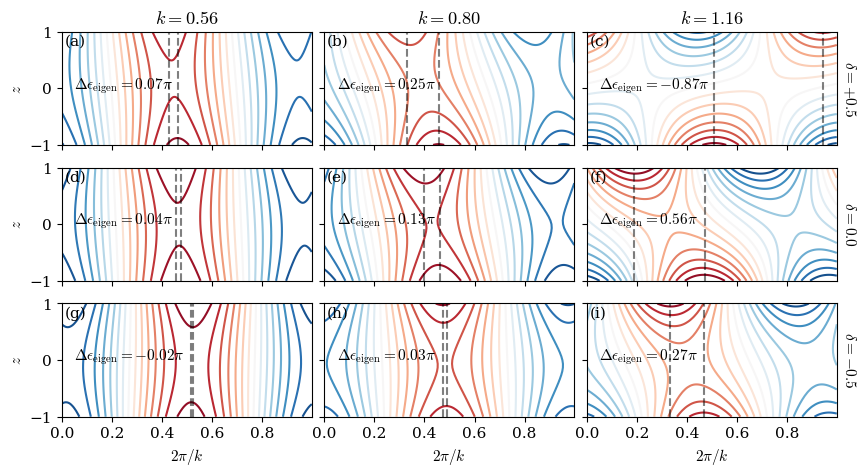

In [11]:
# figure6 (streamfunction in enstrophy norm)
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 5), sharex=True, sharey=True)
for j, delta_idx in enumerate([0, 1, 2]):
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Eady_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        field = np.real(field0[:, :, i, j, ll])
        cs = ax.contour(x_vec/(2.0*np.pi/k), z_vec, field, levels=16, cmap='RdBu_r')
        x_loc_T = x_vec[np.argmax(field[-1, :])] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(field[0, :])] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-1, 1], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-1, 1], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.50, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={Eady_k_max[k_idx, ll]:.2f}$" if j == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\delta={delta_vec[idx]:+.1f}$" if delta_vec[idx] != 0 else r"$\delta=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
fig.subplots_adjust(wspace=0.05)
# fig.savefig('figure/figure6.pdf', bbox_inches='tight')

## 3) Supplementary figures that didn't go into paper

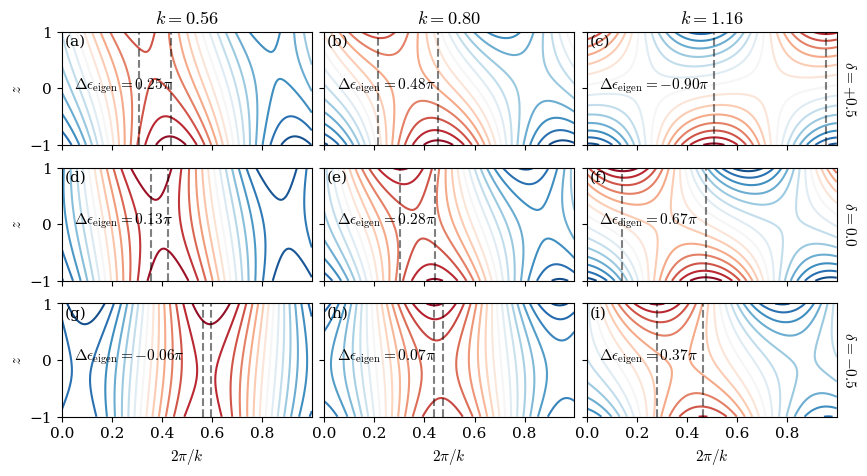

In [12]:
# streamfunction in energy norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 5), sharex=True, sharey=True)
for j, delta_idx in enumerate([0, 1, 2]):
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Eady_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        field = np.real(field0_enr[:, :, i, j, ll])
        cs = ax.contour( x_vec/(2.0*np.pi/k), z_vec, field, levels=16, cmap='RdBu_r')
        x_loc_T = x_vec[np.argmax(field[-1, :])] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(field[0, :])] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-1, 1], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-1, 1], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.50, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={Eady_k_max[k_idx, ll]:.2f}$" if j == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\delta={delta_vec[idx]:+.1f}$" if delta_vec[idx] != 0 else r"$\delta=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
fig.subplots_adjust(wspace=0.05)
# fig.savefig('figure/figure7.pdf', bbox_inches='tight')

### checks for operator normality 

Matrix norm should be very close to zero. Used $L_{1,1}$ here.

l = 0.0
  ens min at k = 0.841, matrix norm = 1.6885e-01
  enr min at k = 0.733, matrix norm = 2.7989e-01
  ens min at k = 1.031, matrix norm = 2.7668e-03
  enr min at k = 0.955, matrix norm = 3.5643e-03
  ens min at k = 1.272, matrix norm = 4.4761e-02
  enr min at k = 1.240, matrix norm = 5.0676e-02


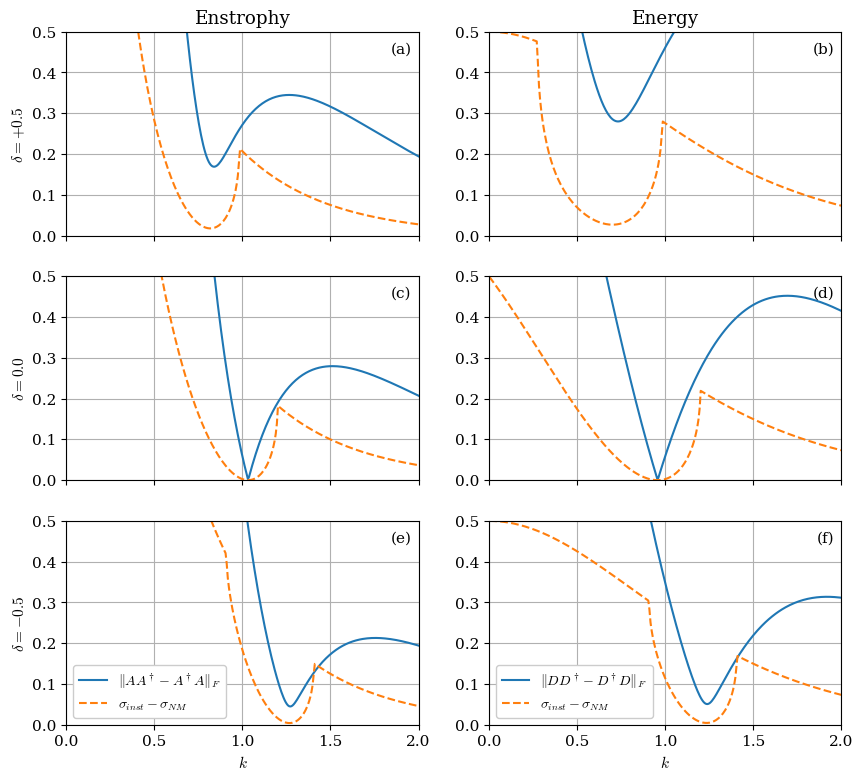

In [13]:
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
ll = 0
for j in range(3):
    ax = axs[j, 0]
    ax.plot(k_vec, normality[:, j, ll], label=r'$\|AA^\dagger-A^\dagger A\|_F$')
    diff = np.abs(Eady_growth_ens[:, j, ll] - Eady_growth_NM[:, j, ll])
    ax.plot(k_vec, diff,'--', label=r'$\sigma_{inst}-\sigma_{NM}$')
    ax.set_title('Enstrophy' if j == 0 else "")
    ax.set_ylim(0.0, 0.5)
    ax.text(0.98, 0.95, f"({letters[2*j]})", transform=ax.transAxes, ha='right', va='top')
    ax.set_ylabel(rf'$\delta={delta_vec[j]:+.1f}$' if delta_vec[j] != 0 else r'$\delta=0.0$', rotation=90)
    
    ax = axs[j, 1]
    ax.plot(k_vec, normality_enr[:, j, ll], label=r'$\|DD^\dagger-D^\dagger D\|_F$')
    diff = np.abs(Eady_growth_enr[:, j, ll] - Eady_growth_NM[:, j, ll])
    ax.plot(k_vec, diff,'--', label=r'$\sigma_{inst}-\sigma_{NM}$')
    ax.set_title('Energy' if j == 0 else "")
    ax.set_ylim(0.0, 0.5)
    ax.text(0.98, 0.95, f"({letters[2*j+1]})", transform=ax.transAxes, ha='right', va='top')  

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 2)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")
    ax.legend(loc='lower left', framealpha=1.0, fontsize=10.0)

print(f"l = {l_vec[0]}")
for j in range(3):
    dum = normality[:, j, ll]
    print(f"  ens min at k = {k_vec[np.where(dum == np.min(dum))].item():.3f}, matrix norm = {np.min(dum):.4e}")
    dum = normality_enr[:, j, ll]
    print(f"  enr min at k = {k_vec[np.where(dum == np.min(dum))].item():.3f}, matrix norm = {np.min(dum):.4e}")

### sample calculations for $l\neq0$

Took $l=0.5$ as the gravest non-trivial mode.

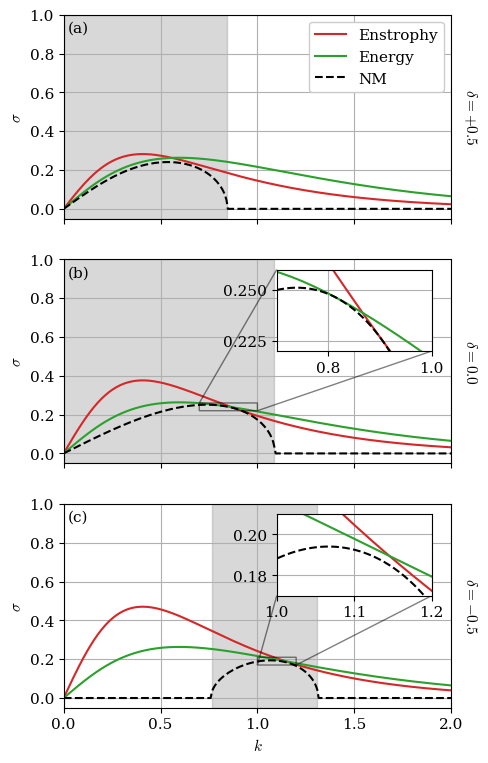

In [14]:
# figure2 （growth rate)
fig, axs = plt.subplots(3, 1, figsize=(5, 9), sharex=True)
ll = 1
for j, ax in enumerate(axs):
    ax.plot(k_vec, Eady_growth_ens[:, j, ll],'C3', label='Enstrophy')
    ax.plot(k_vec, Eady_growth_enr[:, j, ll],'C2', label='Energy')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', label='NM')
    ax.set_xlim(0, 2)
    ax.set_ylim(-0.05, 1.0)
    ax.set_ylabel(r"$\sigma$")
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.grid()
    ax.set_xticks([0, 0.5, 1.0, 1.5, 2.0])
    ax.text(0.01, 0.97, f"({letters[j]})", transform=ax.transAxes, ha='left', va='top')
    if j == 1:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Eady_growth_ens[:, j, ll],'C3')
        ax_inset.plot(k_vec, Eady_growth_enr[:, j, ll],'C2')
        ax_inset.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(0.7, 1.0)
        ax_inset.set_ylim(0.22, 0.26)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")
        
    if j == 2:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Eady_growth_ens[:, j, ll],'C3')
        ax_inset.plot(k_vec, Eady_growth_enr[:, j, ll],'C2')
        ax_inset.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(1.0, 1.2)
        ax_inset.set_ylim(0.17, 0.21)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")

for row, ax in enumerate(axs):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1].set_xlabel(r"$k$")
axs[0].legend(loc='upper right', framealpha=1.0)

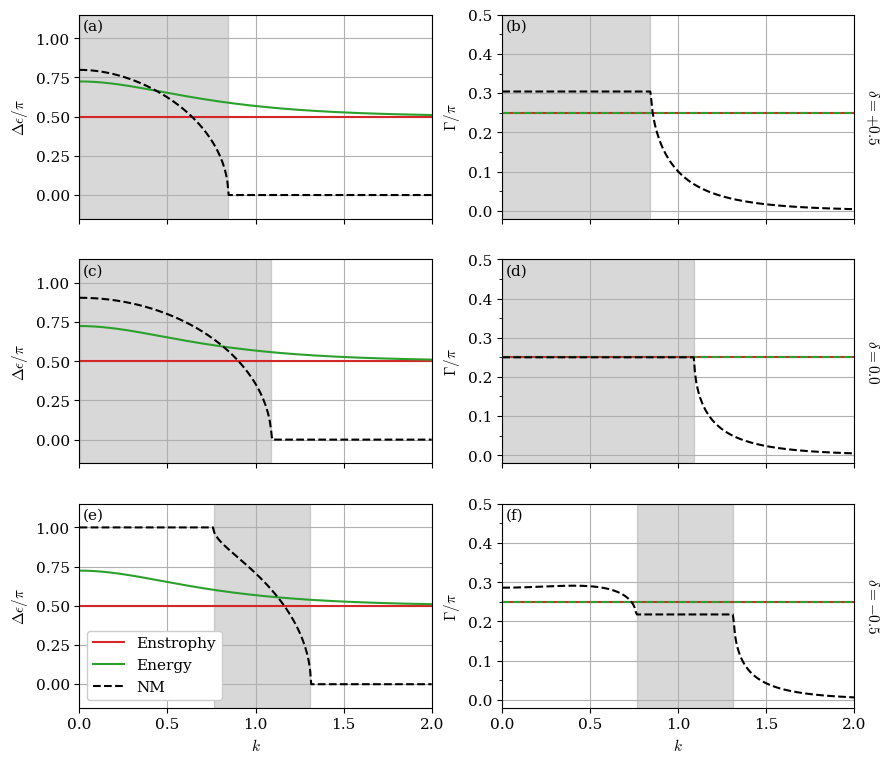

In [15]:
# figure3 (CRW quantities)
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
ll = 1
for j in range(3):
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    ax.plot(k_vec, Eady_eps_ens[:, j, ll]/np.pi, 'C3', label='Enstrophy')
    ax.plot(k_vec, Eady_eps_enr[:, j, ll]/np.pi, 'C2', label='Energy')
    ax.plot(k_vec, Eady_eps_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylim([-0.15, 1.15])
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    ax.set_ylabel(r'$\Delta\epsilon/\pi$')
    
    ax = axs[j, 1]
    ax.plot(k_vec, Eady_Gamma_ens[:, j, ll]/np.pi, 'C3', label='Enstrophy')
    ax.plot(k_vec, Eady_Gamma_enr[:, j, ll]/np.pi, 'C2--', label='Energy')
    ax.plot(k_vec, Eady_Gamma_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylabel(r'$\Gamma/\pi$')
    ax.set_ylim(-0.02, 0.5)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top')  

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 2)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1,0].legend(loc='lower left', framealpha=1.0)

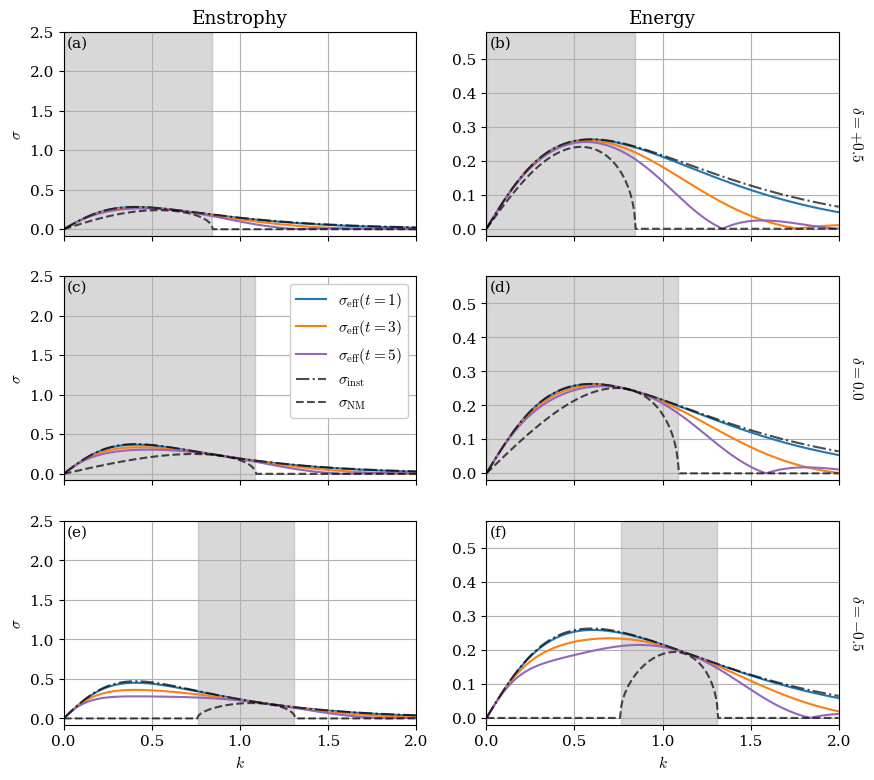

In [16]:
# figure4 (effective optimal growth rate)
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
colors = ['C0', 'C1', 'C4']
ll = 1
for j in range(3):
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Eady_effective_ens[:, j, d, ll], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Eady_growth_ens[:, j, ll], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', alpha=0.7, label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Enstrophy' if j == 0 else "")
    ax.set_ylim(-0.08, 2.5)
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    ax.set_ylabel(r"$\sigma$")
    
    ax = axs[j, 1]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Eady_effective_enr[:, j, d, ll], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Eady_growth_enr[:, j, ll], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', alpha=0.7, label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Energy' if j == 0 else "")
    ax.set_ylim(-0.02, 0.58)
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top')

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 2)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

axs[1,0].legend(loc='upper right', framealpha=1.0)

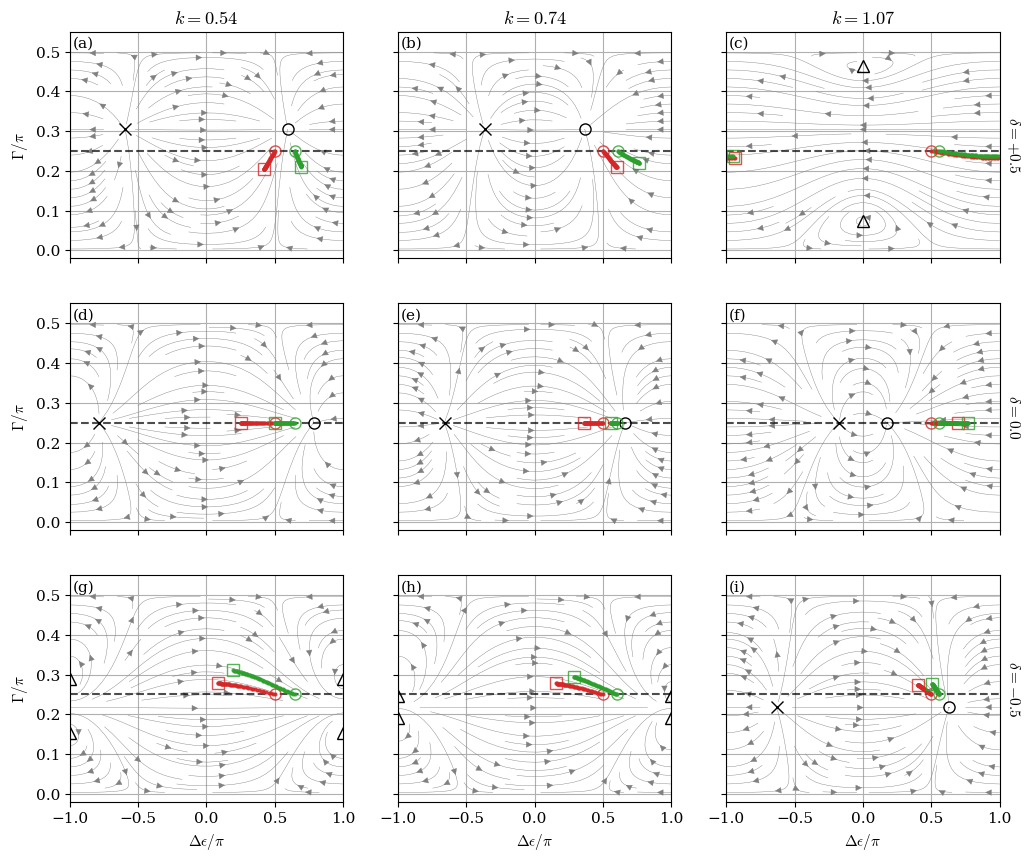

In [17]:
# figure5 (phase portrait)
dummy = 0

ll = 1
l = l_vec[ll]
k_vals = Eady_k_max[:, ll]
T_vecs = np.linspace(1e-3, 5.0, 51)
# T_vecs = np.linspace(50, 500, 51)
fig, axs = plt.subplots(3,3,figsize=(12,10),sharex=True,sharey=True)

for row, delta in enumerate(delta_vec):
    for col, k in enumerate(k_vals):
        ax = axs[row, col]
        deps_grid, gamma_grid = np.meshgrid(np.linspace(-np.pi, np.pi, 101),np.linspace(0.01, np.pi/2 - 0.01, 101))
        points = np.asarray([deps_grid, gamma_grid])
        eps_dot, gamma_dot = dF_eady(points,k,delta,l,Bu)
        ax.streamplot(deps_grid/np.pi,gamma_grid/np.pi,eps_dot,gamma_dot, color='gray', linewidth=0.3,density=0.8)
        ax.plot([-1.0, 1.0], [0.25, 0.25], 'k--', alpha=0.7)

        # Plot fixed points
        A = Eady_A(k, l, delta, Bu)
        eigvals, eigvecs = np.linalg.eig(A)
        growth = np.max(np.real(eigvals))
        if growth > 1e-3:
            pos_root = get_root_eady(dF_eady, k, delta, guess_init=[0.25*np.pi, 0.25*np.pi])
            neg_root = get_root_eady(dF_eady ,k, delta, guess_init=[-0.25*np.pi, 0.25*np.pi])
            ax.plot(pos_root[0]/np.pi,pos_root[1]/np.pi,'ko',markersize=8,markerfacecolor='none',markeredgewidth=1)
            ax.plot(neg_root[0]/np.pi,neg_root[1]/np.pi,'kx',markersize=8,markeredgewidth=1)

        else:
            pos_root = get_root_eady(dF_eady, k, delta, guess_init=[0.25*np.pi, 0.25*np.pi])
            neg_root = get_root_eady(dF_eady ,k, delta, guess_init=[-0.25*np.pi, 0.1*np.pi])
            plot_root(ax, pos_root)
            plot_root(ax, neg_root)     

        # Plot enstrophy-optimal points
        deps0_ens, gamma0_ens = compute_optimal(T_vecs, A, np.eye(2))
        ax.plot(deps0_ens/np.pi,gamma0_ens/np.pi,'C3.', ms=4, alpha=0.8, label='Enstrophy')
        ax.plot(deps0_ens[0]/np.pi,gamma0_ens[0]/np.pi,'C3o',markerfacecolor='none',markersize=8, alpha=0.8, label=rf't={int(T_vecs[0])}')
        ax.plot(deps0_ens[-1]/np.pi,gamma0_ens[-1]/np.pi,'C3s',markerfacecolor='none',markersize=8, alpha=0.8, label=rf't={int(T_vecs[-1])}')
        
        # Plot energy-optimal points
        M = Eady_M(k, l, Bu)
        deps0_enr, gamma0_enr = compute_optimal(T_vecs, A, M)
        ax.plot(deps0_enr/np.pi,gamma0_enr/np.pi,'C2.', ms=4, alpha=0.8, label='Energy')
        ax.plot(deps0_enr[0]/np.pi,gamma0_enr[0]/np.pi,'C2o',markerfacecolor='none',markersize=8, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[0])}$')
        ax.plot(deps0_enr[-1]/np.pi,gamma0_enr[-1]/np.pi,'C2s',markerfacecolor='none',markersize=8, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[-1])}$')

        ax.set_ylim([-0.02, 0.55])
        ax.grid()
        ax.set_title(rf'$k={k:.2f}$' if row == 0 else "")
        
        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$\Delta\epsilon/\pi$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$\Gamma/\pi$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

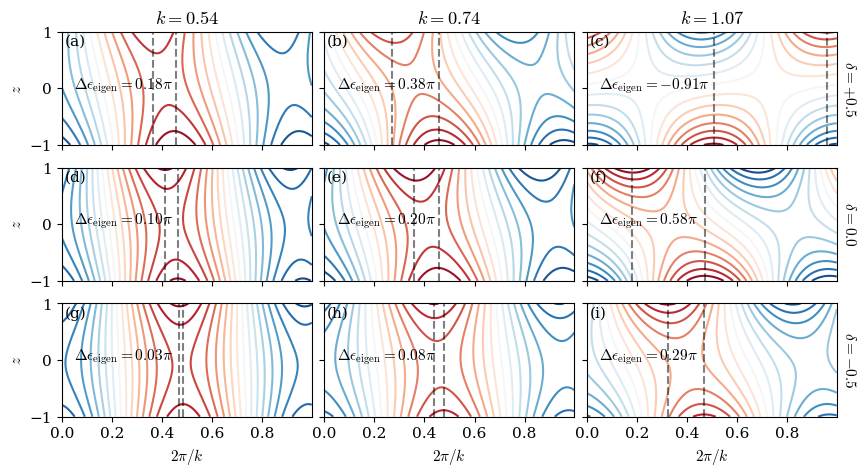

In [18]:
# figure6 (streamfunction in enstrophy norm)
dummy = 0
ll = 1
fig, axs = plt.subplots(3, 3, figsize=(10, 5), sharex=True, sharey=True)
for j, delta_idx in enumerate([0, 1, 2]):
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Eady_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        field = np.real(field0[:, :, i, j, ll])
        cs = ax.contour(x_vec/(2.0*np.pi/k), z_vec, field, levels=16, cmap='RdBu_r')
        x_loc_T = x_vec[np.argmax(field[-1, :])] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(field[0, :])] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-1, 1], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-1, 1], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.50, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={Eady_k_max[k_idx, ll]:.2f}$" if j == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\delta={delta_vec[idx]:+.1f}$" if delta_vec[idx] != 0 else r"$\delta=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
fig.subplots_adjust(wspace=0.05)

### analogous investigation into other norms

KE, PE and boundary pressure ones. Compute first before plotting.

In [19]:
def Eady_K(k, l, Bu):   # Kinetic energy matrix for Eady
    mu = Bu * np.sqrt(k**2 + l**2)
    M = np.array([
            [np.cosh(2*mu)/(2*mu*np.sinh(2*mu)) + 1/np.sinh(2*mu)**2, np.cosh(2*mu)/np.sinh(2*mu)**2 + 1/(2*mu*np.sinh(2*mu))],
            [np.cosh(2*mu)/np.sinh(2*mu)**2 + 1/(2*mu*np.sinh(2*mu)), np.cosh(2*mu)/(2*mu*np.sinh(2*mu)) + 1/np.sinh(2*mu)**2]
        ])
    return M

def Eady_PE(k, l, Bu):   # Potential energy matrix for Eady
    mu = Bu * np.sqrt(k**2 + l**2)
    M = np.array([
            [np.cosh(2*mu)/(2*mu*np.sinh(2*mu)) - 1/np.sinh(2*mu)**2, 1/(2*mu*np.sinh(2*mu)) - np.cosh(2*mu)/np.sinh(2*mu)**2],
            [1/(2*mu*np.sinh(2*mu)) - np.cosh(2*mu)/np.sinh(2*mu)**2, np.cosh(2*mu)/(2*mu*np.sinh(2*mu)) - 1/np.sinh(2*mu)**2]
        ])
    return M

def Eady_P(k, l, Bu):   # Pressure matrix for Eady
    mu = Bu * np.sqrt(k**2 + l**2)
    M = np.array([
                [np.cosh(2*mu)**2+1, 2*np.cosh(2*mu)],
                [2*np.cosh(2*mu), np.cosh(2*mu)**2+1,]
            ])
    M /= (mu*np.sinh(2*mu))**2
    return M

In [20]:
# sloped Eady
# compute growth rate, phase shift and amplitude ratio for other norms
k_vec = np.concat([10 ** np.linspace(-3, -1, 201), np.linspace(1e-1, 2, 301)])
delta_vec = [0.5, 0.0, -0.5]
l = 0
# Bu = 1.0
ll = 0
Eady_growth_ke = np.zeros((len(k_vec), len(delta_vec)))
Eady_eps_ke = np.zeros((len(k_vec), len(delta_vec)))
Eady_Gamma_ke = np.zeros((len(k_vec), len(delta_vec)))
Eady_growth_pe = np.zeros((len(k_vec), len(delta_vec)))
Eady_eps_pe = np.zeros((len(k_vec), len(delta_vec)))
Eady_Gamma_pe = np.zeros((len(k_vec), len(delta_vec)))
Eady_growth_p = np.zeros((len(k_vec), len(delta_vec)))
Eady_eps_p = np.zeros((len(k_vec), len(delta_vec)))
Eady_Gamma_p = np.zeros((len(k_vec), len(delta_vec)))

for j, delta in enumerate(delta_vec):
    for i, k in enumerate(k_vec):
        A = Eady_A(k, l, delta, Bu)
        K = Eady_K(k, l, Bu)    # kinetic energy
        PE = Eady_PE(k, l, Bu)  # potential energy
        P = Eady_P(k, l, Bu)    # pressure
        eigvals, eigvecs = eig(A)
        idx = np.argmax(np.real(eigvals))
        if Eady_growth_NM[i, j, ll]>1e-4:
            q = eigvecs[:, idx]
        else:
            id = np.argmax(np.imag(eigvals))
            q = eigvecs[:, id]

        growth, q = instantaneous(A, K)
        Eady_growth_ke[i, j] = np.real(growth)
        Eady_eps_ke[i, j], Eady_Gamma_ke[i, j] = state_to_phase(q)
        Eady_eps_ke[i, j] = np.arccos(np.cos(Eady_eps_ke[i, j]))

        growth, q = instantaneous(A, PE)
        Eady_growth_pe[i, j] = np.real(growth)
        Eady_eps_pe[i, j], Eady_Gamma_pe[i, j] = state_to_phase(q)
        Eady_eps_pe[i, j] = np.arccos(np.cos(Eady_eps_pe[i, j]))

        growth, q = instantaneous(A, P)
        Eady_growth_p[i, j] = np.real(growth)
        Eady_eps_p[i, j], Eady_Gamma_p[i, j] = state_to_phase(q)
        Eady_eps_p[i, j] = np.arccos(np.cos(Eady_eps_p[i, j]))

In [21]:
# effective optimal growth
t_vals = [1.0, 3.0, 5.0]
l = 0.0
# Bu = 1.0

Eady_effective_ke = np.zeros((len(k_vec), len(delta_vec), len(t_vals)))
Eady_effective_pe = np.zeros((len(k_vec), len(delta_vec), len(t_vals)))
Eady_effective_p = np.zeros((len(k_vec), len(delta_vec), len(t_vals)))

for j, delta in enumerate(delta_vec):
    for i, k in enumerate(k_vec):
        A = Eady_A(k, l, delta, Bu)
        K = Eady_K(k, l, Bu)
        PE = Eady_PE(k, l, Bu)
        P = Eady_P(k, l, Bu)
        for d, t in enumerate(t_vals):
            amp_ke, _, _ = finite_time_optimal(t, A, K)
            amp_pe, _, _ = finite_time_optimal(t, A, PE)
            amp_p, _, _ = finite_time_optimal(t, A, P)
            Eady_effective_ke[i, j, d] = np.log(amp_ke)/t
            Eady_effective_pe[i, j, d] = np.log(amp_pe)/t
            Eady_effective_p[i, j, d] = np.log(amp_p)/t

In [22]:
# z_vec = np.linspace(-1, 1, 31)
t = 5.0
psi0_B_ke = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)
psi0_T_ke = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)
psi0_B_pe = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)
psi0_T_pe = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)
psi0_B_p = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)
psi0_T_p = np.zeros((len(z_vec), 501, 3, 3), dtype=complex)

for j, idx in enumerate([0, 1, 2]):
    delta = delta_vec[idx]
    for i, k_idx in enumerate([0, 1, 2]):
        k = Eady_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        mu = Bu * np.sqrt(k**2 + l**2)
        A = Eady_A(k, l, delta, Bu)
        K = Eady_K(k, l, Bu)
        PE = Eady_PE(k, l, Bu)
        P = Eady_P(k, l, Bu)
        _, q0_ke, _ = finite_time_optimal(t, A, K)
        _, q0_pe, _ = finite_time_optimal(t, A, PE)
        _, q0_p, _ = finite_time_optimal(t, A, P)

        q0_ke[0] /= q0_ke[1]
        q0_ke[1] = 1.0
        q0_pe[0] /= q0_pe[1]
        q0_pe[1] = 1.0
        q0_p[0] /= q0_p[1]
        q0_p[1] = 1.0

        Z = z_vec[:, None]
        X = x_vec[None, :]
        psi0_B_ke[:, :, i, j] = np.exp(zi * k * X) * (-q0_ke[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
        psi0_T_ke[:, :, i, j] = np.exp(zi * k * X) * (-q0_ke[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

        psi0_B_pe[:, :, i, j] = np.exp(zi * k * X) * (-q0_pe[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
        psi0_T_pe[:, :, i, j] = np.exp(zi * k * X) * (-q0_pe[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))

        psi0_B_p[:, :, i, j] = np.exp(zi * k * X) * (-q0_p[1] *np.cosh(mu * (1.0 - Z))) / (mu * np.sinh(2.0 * mu))
        psi0_T_p[:, :, i, j] = np.exp(zi * k * X) * (-q0_p[0] * np.cosh(mu * (1.0 + Z))) / (mu * np.sinh(2.0 * mu))


field0_ke = psi0_T_ke + psi0_B_ke
# diff0_ke = np.angle(field0_ke[-1, 0, :, :]/field0_ke[0, 0, :, :])
field0_pe = psi0_T_pe + psi0_B_pe
# diff0_pe = np.angle(field0_pe[-1, 0, :, :]/field0_pe[0, 0, :, :])
field0_p = psi0_T_p + psi0_B_p
# diff0_p = np.angle(field0_p[-1, 0, :, :]/field0_p[0, 0, :, :])

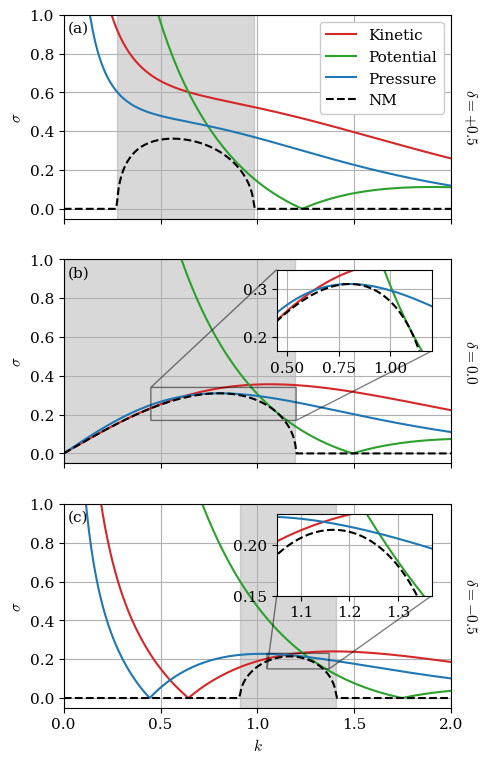

In [23]:
# figure2 （growth rate)
fig, axs = plt.subplots(3, 1, figsize=(5, 9), sharex=True)
ll = 0
for j, ax in enumerate(axs):
    ax.plot(k_vec, Eady_growth_ke[:, j],'C3', label='Kinetic')
    ax.plot(k_vec, Eady_growth_pe[:, j],'C2', label='Potential')
    ax.plot(k_vec, Eady_growth_p[:, j],'C0', label='Pressure')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', label='NM')
    ax.set_xlim(0, 2)
    ax.set_ylim(-0.05, 1.0)
    ax.set_ylabel(r"$\sigma$")
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.grid()
    ax.set_xticks([0, 0.5, 1.0, 1.5, 2.0])
    ax.text(0.01, 0.97, f"({letters[j]})", transform=ax.transAxes, ha='left', va='top')
    if j == 1:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Eady_growth_ke[:, j],'C3')
        ax_inset.plot(k_vec, Eady_growth_pe[:, j],'C2')
        ax_inset.plot(k_vec, Eady_growth_p[:, j],'C0')
        ax_inset.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(0.45, 1.2)
        ax_inset.set_ylim(0.17, 0.34)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")
        
    if j == 2:
        ax_inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
        ax_inset.plot(k_vec, Eady_growth_ke[:, j],'C3')
        ax_inset.plot(k_vec, Eady_growth_pe[:, j],'C2')
        ax_inset.plot(k_vec, Eady_growth_p[:, j],'C0')
        ax_inset.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--')
        
        ax_inset.set_xlim(1.05, 1.37)
        ax_inset.set_ylim(0.15, 0.23)
        ax_inset.grid()
        ax.indicate_inset_zoom(ax_inset, edgecolor="black")

for row, ax in enumerate(axs):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[-1].set_xlabel(r"$k$")
axs[0].legend(loc='upper right', framealpha=1.0)
# fig.savefig('figure/figure2.pdf', bbox_inches='tight')

In [24]:
delta_ind = 1

print(f"ens      : k_opt = {k_vec[np.where(Eady_growth_ens[:, delta_ind] == np.max(Eady_growth_ens[:, 1]))[0][0]]:.6f}")
print(f"E tot    : k_opt = {k_vec[np.where(Eady_growth_enr[:, delta_ind] == np.max(Eady_growth_enr[:, 1]))[0][0]]:.6f}")
print(f"PE       : k_opt = {k_vec[np.where(Eady_growth_pe[:, delta_ind] == np.max(Eady_growth_pe[:, 1]))[0][0]]:.6f}")
print(f"KE       : k_opt = {k_vec[np.where(Eady_growth_ke[:, delta_ind] == np.max(Eady_growth_ke[:, 1]))[0][0]]:.6f}")
print(f"surf pres: k_opt = {k_vec[np.where(Eady_growth_p[:, delta_ind] == np.max(Eady_growth_p[:, 1]))[0][0]]:.6f}")
print(f"NM       : k_opt = {k_vec[np.where(Eady_growth_NM[:, delta_ind, ll] == np.max(Eady_growth_NM[:, 1, ll]))[0][0]]:.6f}")

ens      : k_opt = 0.001000
E tot    : k_opt = 0.001000
PE       : k_opt = 0.001000
KE       : k_opt = 1.062667
surf pres: k_opt = 0.803000
NM       : k_opt = 0.803000


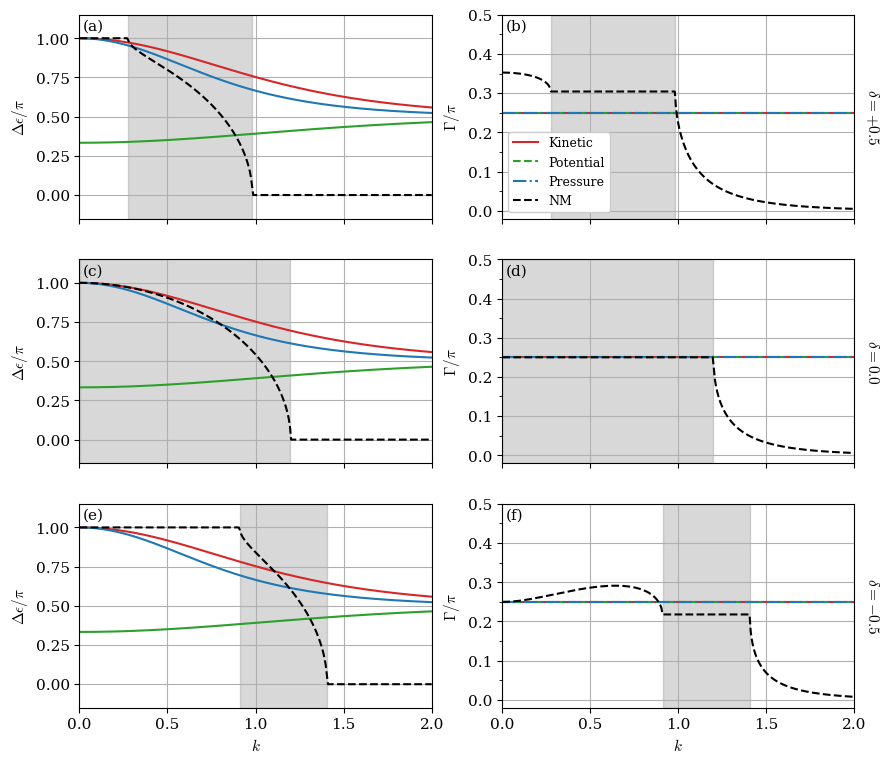

In [25]:
# CRW quantities
fig, axs = plt.subplots(3, 2,figsize=(10, 9),sharex=True)
ll = 0
for j in range(3):
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    ax.plot(k_vec, Eady_eps_ke[:, j]/np.pi, 'C3', label='Kinetic')
    ax.plot(k_vec, Eady_eps_pe[:, j]/np.pi, 'C2', label='Potential')
    ax.plot(k_vec, Eady_eps_p[:, j]/np.pi, 'C0', label='Pressure')
    ax.plot(k_vec, Eady_eps_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylim([-0.15, 1.15])
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    ax.set_ylabel(r'$\Delta\epsilon/\pi$')
    
    ax = axs[j, 1]
    ax.plot(k_vec, Eady_Gamma_ke[:, j]/np.pi, 'C3', label='Kinetic')
    ax.plot(k_vec, Eady_Gamma_pe[:, j]/np.pi, 'C2--', label='Potential')
    ax.plot(k_vec, Eady_Gamma_p[:, j]/np.pi, 'C0-.', label='Pressure')
    ax.plot(k_vec, Eady_Gamma_NM[:, j, ll]/np.pi, 'k--', label='NM')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_ylabel(r'$\Gamma/\pi$')
    ax.set_ylim(-0.02, 0.5)
    ax.yaxis.set_major_locator(MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top')  

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 2)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))

for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

axs[0,1].legend(loc='lower left', framealpha=1.0, fontsize=9.0)
# fig.savefig('figure/figure3.pdf', bbox_inches='tight')

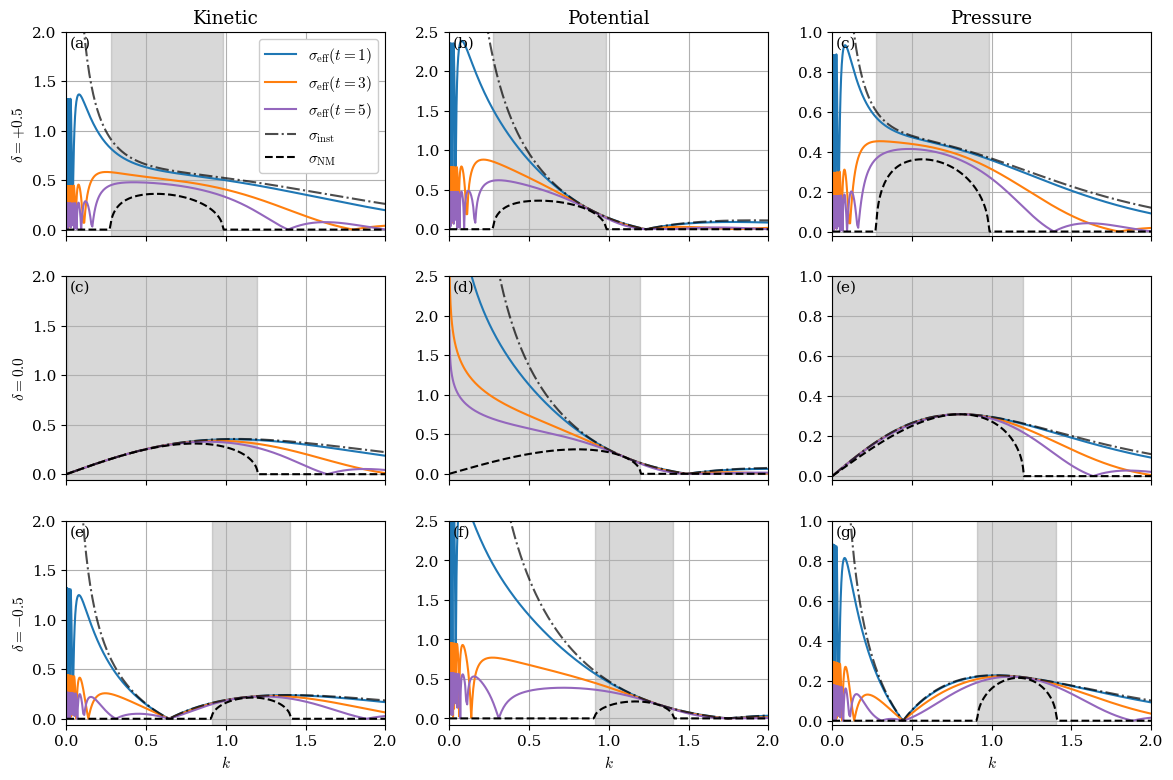

In [26]:
# effective optimal growth
fig, axs = plt.subplots(3, 3,figsize=(14, 9),sharex=True)
colors = ['C0', 'C1', 'C4']
ll = 0
for j in range(3):
    k_shade_ind = np.where(Eady_growth_NM[:, j, ll] > 1e-3)[0]
    ax = axs[j, 0]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Eady_effective_ke[:, j, d], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Eady_growth_ke[:, j], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Kinetic' if j == 0 else "")
    ax.set_ylim(-0.06, 2.0)
    # ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.text(0.01, 0.98, f"({letters[2*j]})", transform=ax.transAxes, ha='left', va='top')
    ax.set_ylabel(rf'$\delta={delta_vec[j]:+.1f}$' if delta_vec[j] != 0 else r'$\delta=0.0$', rotation=90)
    
    ax = axs[j, 1]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Eady_effective_pe[:, j, d], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Eady_growth_pe[:, j], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Potential' if j == 0 else "")
    ax.set_ylim(-0.08, 2.5)
    ax.text(0.01, 0.98, f"({letters[2*j+1]})", transform=ax.transAxes, ha='left', va='top')

    ax = axs[j, 2]
    for d, t in enumerate(t_vals):
        ax.plot(k_vec, Eady_effective_p[:, j, d], color=colors[d], label=rf'$\sigma_{{\rm eff}}(t={int(t)})$')
    ax.plot(k_vec, Eady_growth_p[:, j], 'k-.', alpha=0.7, label=r'$\sigma_{\rm inst}$')
    ax.plot(k_vec, Eady_growth_NM[:, j, ll], 'k--', label=r'$\sigma_{\rm NM}$')
    ax.axvspan(k_vec[k_shade_ind[0]], k_vec[k_shade_ind[-1]], color='gray', alpha=0.3)
    ax.set_title('Pressure' if j == 0 else "")
    ax.set_ylim(-0.02, 1.0)
    ax.text(0.01, 0.98, f"({letters[2*j+2]})", transform=ax.transAxes, ha='left', va='top') 

for ax in axs.flat:
    ax.grid()
    ax.set_xlim(0, 2)
    ax.xaxis.set_major_locator(MultipleLocator(0.5))


for ax in axs[-1, :]:
    ax.set_xlabel(r"$k$")

axs[0,0].legend(loc='upper right', framealpha=1.0)

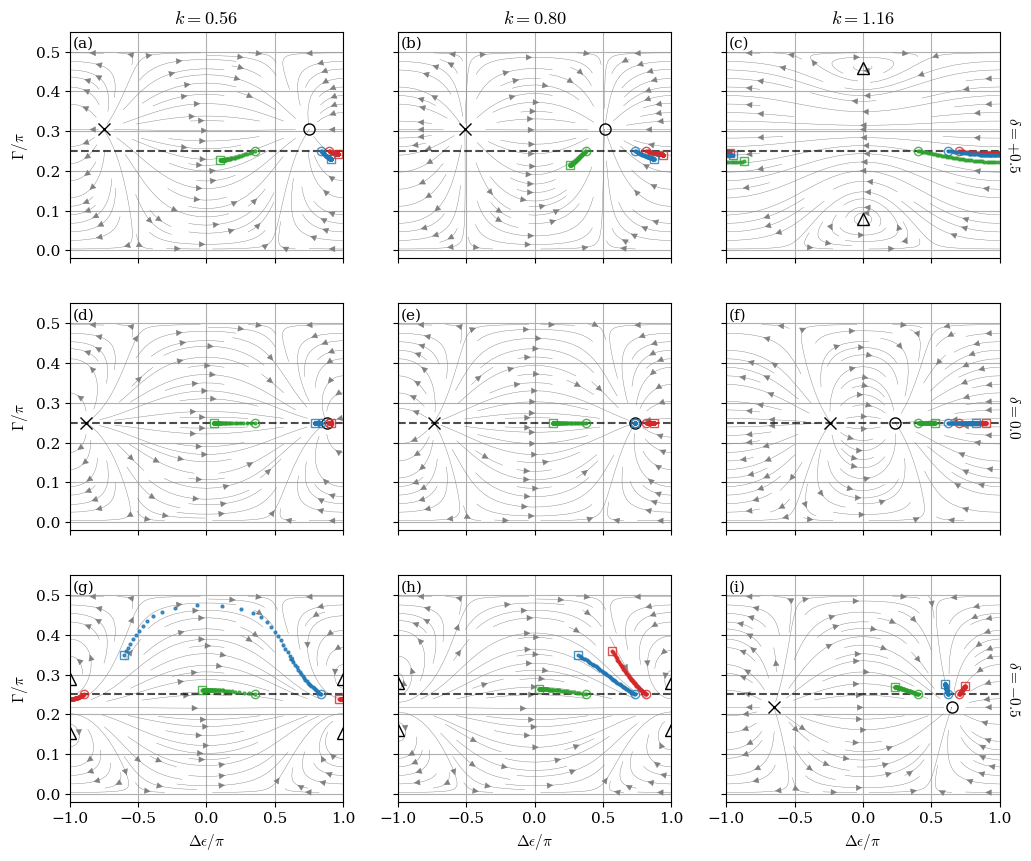

In [27]:
# phase protrait
dummy = 0
ll = 0
k_vals = Eady_k_max[:, ll]
# k_vals = [1.0, 1.5, 2.2]
T_vecs = np.linspace(1e-3, 5.0, 51)
fig, axs = plt.subplots(3,3,figsize=(12,10),sharex=True,sharey=True)
l = l_vec[ll]
for row, delta in enumerate(delta_vec):
    for col, k in enumerate(k_vals):
        ax = axs[row, col]
        deps_grid, gamma_grid = np.meshgrid(np.linspace(-np.pi, np.pi, 101),np.linspace(0.01, np.pi/2 - 0.01, 101))
        points = np.asarray([deps_grid, gamma_grid])
        eps_dot, gamma_dot = dF_eady(points,k,delta,l,Bu)
        ax.streamplot(deps_grid/np.pi,gamma_grid/np.pi,eps_dot,gamma_dot,color='gray', linewidth=0.3,density=0.8)
        ax.plot([-1.0, 1.0], [0.25, 0.25], 'k--', alpha=0.7)

        # Plot fixed points
        A = Eady_A(k, l, delta, Bu)
        eigvals, eigvecs = np.linalg.eig(A)
        growth = np.max(np.real(eigvals))
        if growth > 1e-3:
            pos_root = get_root_eady(dF_eady, k, delta, guess_init=[0.25*np.pi, 0.25*np.pi])
            neg_root = get_root_eady(dF_eady ,k, delta, guess_init=[-0.25*np.pi, 0.25*np.pi])
            ax.plot(pos_root[0]/np.pi,pos_root[1]/np.pi,'ko',markersize=8,markerfacecolor='none',markeredgewidth=1)
            ax.plot(neg_root[0]/np.pi,neg_root[1]/np.pi,'kx',markersize=8,markeredgewidth=1)

        else:
            pos_root = get_root_eady(dF_eady, k, delta, guess_init=[0.25*np.pi, 0.25*np.pi])
            neg_root = get_root_eady(dF_eady ,k, delta, guess_init=[-0.25*np.pi, 0.1*np.pi])
            plot_root(ax, pos_root)
            plot_root(ax, neg_root)

        K = Eady_K(k, l, Bu)
        PE = Eady_PE(k, l, Bu)
        P = Eady_P(k, l, Bu)

        # Plot ke-optimal points
        deps0_ens, gamma0_ens = compute_optimal(T_vecs, A, K)
        ax.plot(deps0_ens/np.pi,gamma0_ens/np.pi,'C3.', ms=4, alpha=0.8, label='Kinetic')
        ax.plot(deps0_ens[0]/np.pi,gamma0_ens[0]/np.pi,'C3o',markerfacecolor='none',markersize=6, alpha=0.8, label=rf't={int(T_vecs[0])}')
        ax.plot(deps0_ens[-1]/np.pi,gamma0_ens[-1]/np.pi,'C3s',markerfacecolor='none',markersize=6, alpha=0.8, label=rf't={int(T_vecs[-1])}')
        
        # Plot pe-optimal points
        deps0_enr, gamma0_enr = compute_optimal(T_vecs, A, PE)
        ax.plot(deps0_enr/np.pi,gamma0_enr/np.pi,'C2.', ms=4, alpha=0.8, label='Potential')
        ax.plot(deps0_enr[0]/np.pi,gamma0_enr[0]/np.pi,'C2o',markerfacecolor='none',markersize=6, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[0])}$')
        ax.plot(deps0_enr[-1]/np.pi,gamma0_enr[-1]/np.pi,'C2s',markerfacecolor='none',markersize=6, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[-1])}$')

        # Plot pressure-optimal points
        deps0_enr, gamma0_enr = compute_optimal(T_vecs, A, P)
        ax.plot(deps0_enr/np.pi,gamma0_enr/np.pi,'C0.', ms=4, alpha=0.8, label='Pressure')
        ax.plot(deps0_enr[0]/np.pi,gamma0_enr[0]/np.pi,'C0o',markerfacecolor='none',markersize=6, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[0])}$')
        ax.plot(deps0_enr[-1]/np.pi,gamma0_enr[-1]/np.pi,'C0s',markerfacecolor='none',markersize=6, alpha=0.8, label=rf'$t_{{\rm target}}={int(T_vecs[-1])}$')

        ax.set_ylim([-0.02, 0.55])
        ax.grid()
        ax.set_title(rf'$k={k:.2f}$' if row == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$\Delta\epsilon/\pi$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$\Gamma/\pi$")

for row, ax in enumerate(axs[:, -1]):
    ax.text(1.05, 0.5, rf'$\delta={delta_vec[row]:+.1f}$' if delta_vec[row] != 0 else r'$\delta=0.0$', transform=ax.transAxes, rotation=-90, va='center', ha='center')

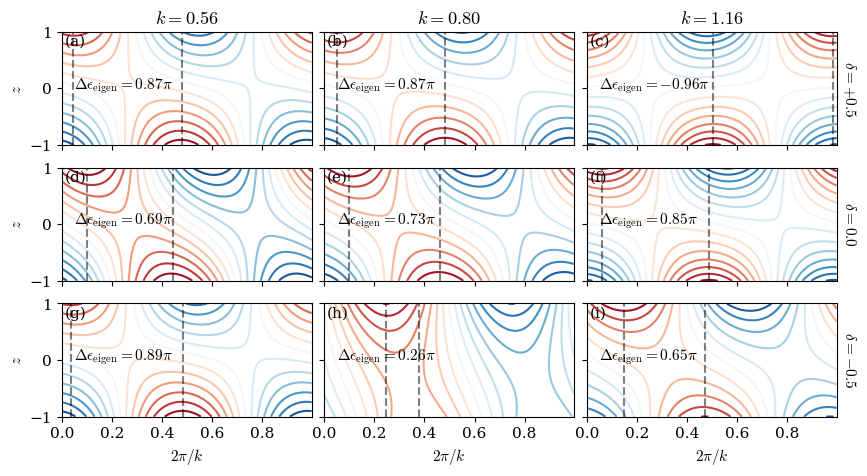

In [28]:
# streamfunction in KE norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 5), sharex=True, sharey=True)
for j, delta_idx in enumerate([0, 1, 2]):
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Eady_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        field = np.real(field0_ke[:, :, i, j])
        cs = ax.contour(x_vec/(2.0*np.pi/k), z_vec, field, levels=16, cmap='RdBu_r')
        x_loc_T = x_vec[np.argmax(field[-1, :])] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(field[0, :])] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-1, 1], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-1, 1], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.50, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={Eady_k_max[k_idx, ll]:.2f}$" if j == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\delta={delta_vec[idx]:+.1f}$" if delta_vec[idx] != 0 else r"$\delta=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
fig.subplots_adjust(wspace=0.05)
# fig.savefig('figure/figure6.pdf', bbox_inches='tight')

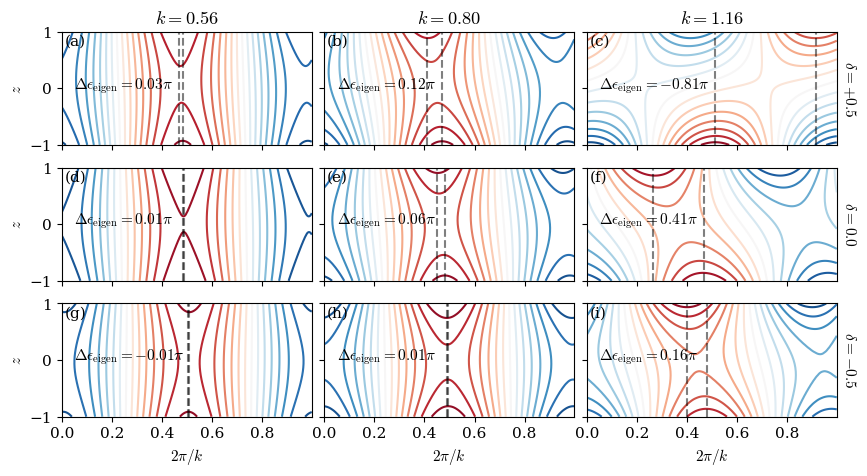

In [29]:
# streamfunction in KE norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 5), sharex=True, sharey=True)
for j, delta_idx in enumerate([0, 1, 2]):
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Eady_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        field = np.real(field0_pe[:, :, i, j])
        cs = ax.contour(x_vec/(2.0*np.pi/k), z_vec, field, levels=16, cmap='RdBu_r')
        x_loc_T = x_vec[np.argmax(field[-1, :])] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(field[0, :])] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-1, 1], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-1, 1], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.50, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={Eady_k_max[k_idx, ll]:.2f}$" if j == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\delta={delta_vec[idx]:+.1f}$" if delta_vec[idx] != 0 else r"$\delta=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
fig.subplots_adjust(wspace=0.05)
# fig.savefig('figure/figure6.pdf', bbox_inches='tight')

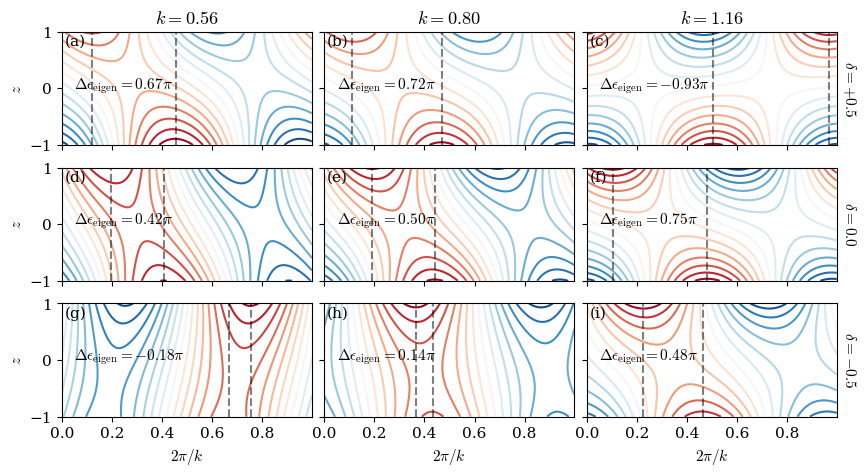

In [30]:
# streamfunction in KE norm
dummy = 0
ll = 0
fig, axs = plt.subplots(3, 3, figsize=(10, 5), sharex=True, sharey=True)
for j, delta_idx in enumerate([0, 1, 2]):
    for i, k_idx in enumerate([0, 1, 2]):
        ax = axs[j, i]
        k = Eady_k_max[k_idx, ll]
        x_vec = np.linspace(0.0, 2.0*np.pi/k, 501, endpoint=False)
        field = np.real(field0_p[:, :, i, j])
        cs = ax.contour(x_vec/(2.0*np.pi/k), z_vec, field, levels=16, cmap='RdBu_r')
        x_loc_T = x_vec[np.argmax(field[-1, :])] / (2.0*np.pi/k)
        x_loc_B = x_vec[np.argmax(field[0, :])] / (2.0*np.pi/k)
        ax.plot([x_loc_T, x_loc_T], [-1, 1], 'k--', alpha=0.5)
        ax.plot([x_loc_B, x_loc_B], [-1, 1], 'k--', alpha=0.5)
        deps = 2*(x_loc_B - x_loc_T)
        ax.text(0.05, 0.50, rf"$\Delta\epsilon_{{\rm eigen}}={deps:.2f}\pi$", transform=ax.transAxes)
        ax.set_title(rf"$k={Eady_k_max[k_idx, ll]:.2f}$" if j == 0 else "")

        ax.text(0.01, 0.98, f"({letters[dummy]})", transform=ax.transAxes, ha='left', va='top')
        dummy += 1

for ax in axs[-1, :]:
    ax.set_xlabel(r"$2\pi/k$")

for ax in axs[:, 0]:
    ax.set_ylabel(r"$z$")

for j, idx in enumerate([0, 1, 2]):
    axs[j,-1].text(1.05,0.5, rf"$\delta={delta_vec[idx]:+.1f}$" if delta_vec[idx] != 0 else r"$\delta=0.0$",
        transform=axs[j,-1].transAxes, rotation=-90, va='center', ha='center')
fig.subplots_adjust(wspace=0.05)
# fig.savefig('figure/figure6.pdf', bbox_inches='tight')